# Lab 6 – Frequency Domain

## Task 1: Filtering in the Frequency Domain (Laplacian)

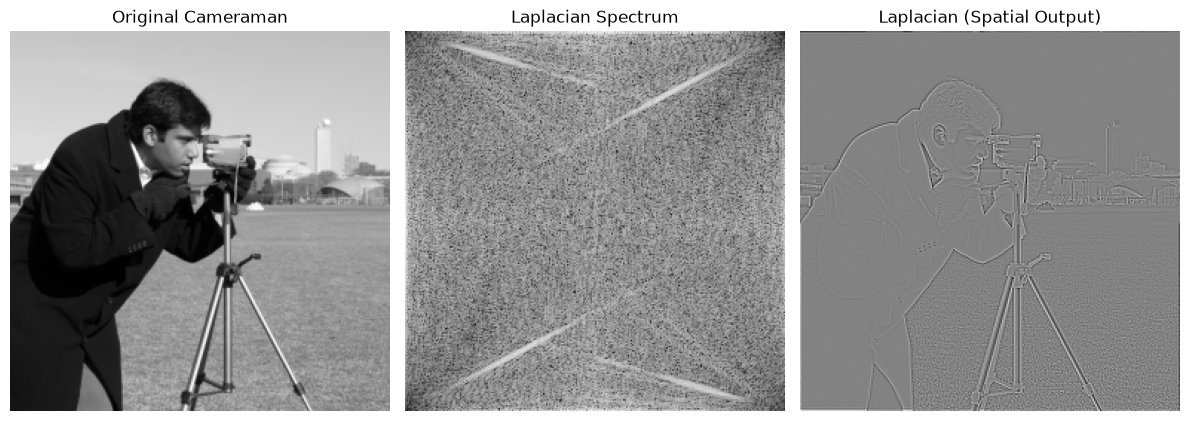

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.transform import resize

# Load cameraman image (already grayscale)
image = data.camera()
image = resize(image, (256, 256))  # Resize for faster FFT (optional)

# Get image size
M, N = image.shape

# Generate frequency grid (centered)
u = np.fft.fftfreq(M).reshape(-1, 1)
v = np.fft.fftfreq(N).reshape(1, -1)

# Compute Laplacian filter in frequency domain
laplacian_filter = -4 * (np.pi ** 2) * (u**2 + v**2)

# Apply 2D FFT
F = np.fft.fft2(image)

# Apply Laplacian filter in frequency domain
F_lap = F * laplacian_filter

# Inverse FFT to get spatial result
laplacian_image = np.fft.ifft2(F_lap).real

# Plot results
plt.figure(figsize=(12, 5))
plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Cameraman')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + np.abs(F_lap)), cmap='gray')
plt.title('Laplacian Spectrum')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(laplacian_image, cmap='gray')
plt.title('Laplacian (Spatial Output)')
plt.axis('off')

plt.tight_layout()
plt.show()

# Assessment
## Task 1: Sobel filters in the frequency domain

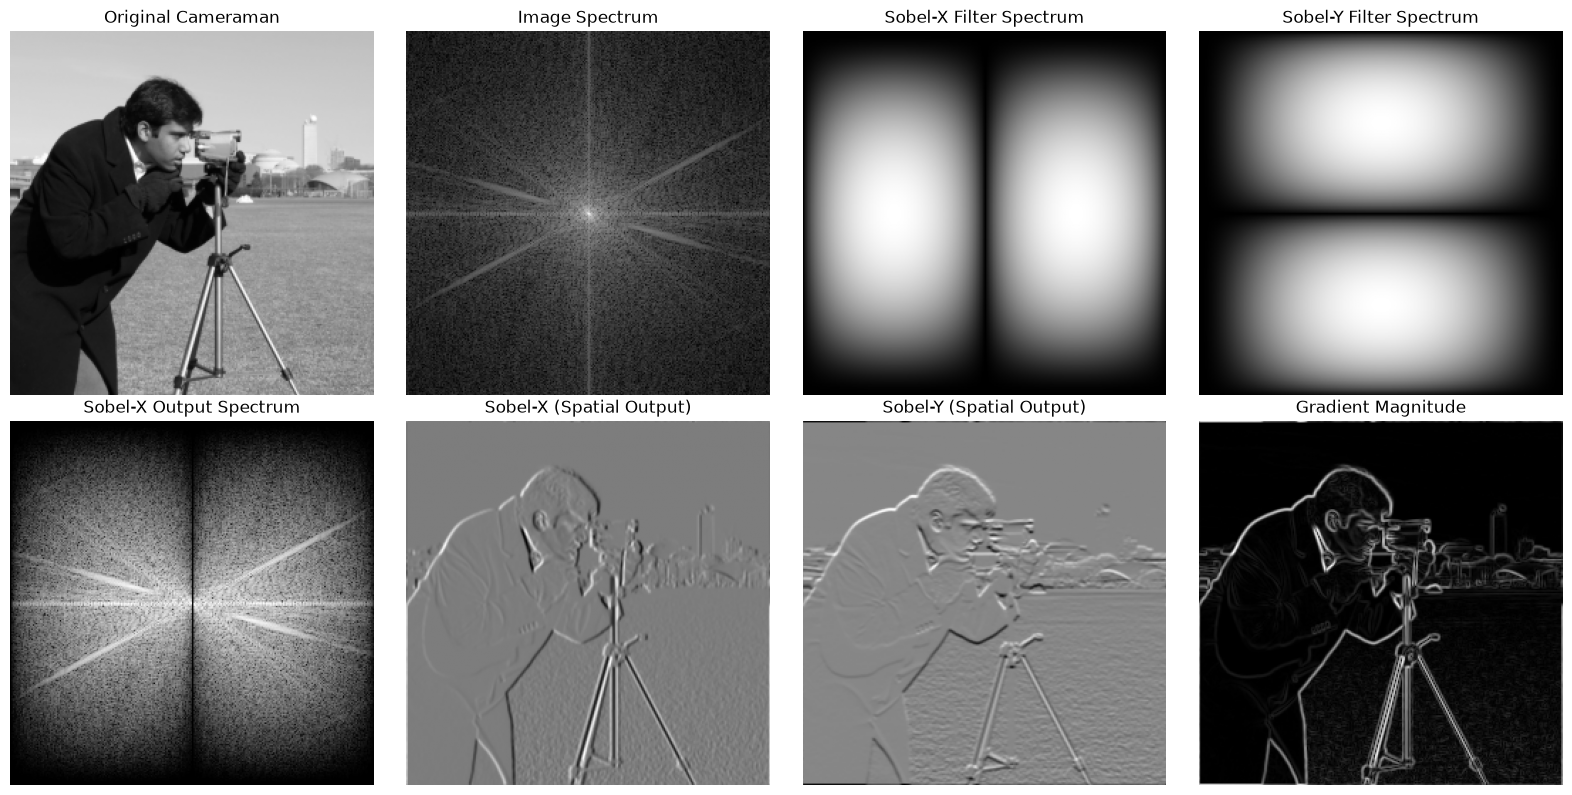

In [2]:
from numpy.fft import fft2, ifft2, fftshift, ifftshift

# Load and resize image
image = resize(data.camera(), (256, 256))
M, N = image.shape

# Sobel filters
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])
sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])

# Proper padding and centering of kernel in spatial domain
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape
    # Find center coordinates
    cy, cx = ph // 2, pw // 2
    # Insert kernel centered at the image center
    padded[cy - kh//2:cy - kh//2 + kh, cx - kw//2:cx - kw//2 + kw] = kernel
    return fft2(ifftshift(padded))  # Shift before FFT to place (0,0) at top-left

# Compute FFT of image
F = fft2(image)

# FFT of centered Sobel filters (use the provided function)
Hx = center_embed_kernel(sobel_x, (M, N))
Hy = center_embed_kernel(sobel_y, (M, N))

# Multiply in the frequency domain
Gx_freq = F * Hx
Gy_freq = F * Hy

# Back to the spatial domain
Gx = ifft2(Gx_freq).real
Gy = ifft2(Gy_freq).real
G = np.sqrt(Gx**2 + Gy**2)  # gradient magnitude

# Plot
def spec(X):
    return np.log(1 + np.abs(fftshift(X)))

fig, ax = plt.subplots(2, 4, figsize=(16, 8))
ax[0, 0].imshow(image, cmap='gray');            ax[0, 0].set_title('Original Cameraman')
ax[0, 1].imshow(spec(F), cmap='gray');          ax[0, 1].set_title('Image Spectrum')
ax[0, 2].imshow(spec(Hx), cmap='gray');         ax[0, 2].set_title('Sobel-X Filter Spectrum')
ax[0, 3].imshow(spec(Hy), cmap='gray');         ax[0, 3].set_title('Sobel-Y Filter Spectrum')
ax[1, 0].imshow(spec(Gx_freq), cmap='gray');    ax[1, 0].set_title('Sobel-X Output Spectrum')
ax[1, 1].imshow(Gx, cmap='gray');               ax[1, 1].set_title('Sobel-X (Spatial Output)')
ax[1, 2].imshow(Gy, cmap='gray');               ax[1, 2].set_title('Sobel-Y (Spatial Output)')
ax[1, 3].imshow(G, cmap='gray');                ax[1, 3].set_title('Gradient Magnitude')
for a in ax.ravel():
    a.axis('off')
plt.tight_layout()
plt.show()

**Observation:** Sobel-X highlights vertical edges and Sobel-Y highlights horizontal edges. Both remove the smooth background, and the gradient magnitude combines them.